# Placing a published score in the distribution of its own protocol: the 0.943 of the stacking ensemble

**Level 3: State of the art** · Needs: 04-benchmark-protocol/01-three-ways-to-split-the-same-97-blasts, 04-benchmark-protocol/02-scores-the-null-and-the-interval · Reading time: about 30 minutes

## Objectives

The most recent published predictor on this corpus is a stacking ensemble reported at a variance explained of 0.943. The figure comes from one random 80/20 split. This notebook asks the question a single number cannot answer: where does 0.943 fall among the scores the same protocol gives on other draws, and what happens to the score when the campaign is held out?

By the end you will have:

- refitted the stacking ensemble and the polynomial-kernel support vector regression on 100 random 80/20 draws and placed each published figure in the distribution of its own protocol;
- repeated the draws after collapsing the duplicated input vectors, to test whether duplicates explain the gap;
- measured the gap between the random-split median and the leave-one-site-out score, and matched the committed benchmark.

## Setup

Install the packages with the exact pins of `notebooks/requirements.txt`. The engine is `blastfrag`, published on PyPI; the other packages are its numerical base and the plotting library.

```bash
pip install blastfrag==0.4.0 numpy==2.5.3 matplotlib==3.11.2
```

This cell imports nothing from the notebook yet: it reads the installed versions from the package metadata and prints them, so the output records exactly which engine produced every number below.

In [1]:
# Print the installed version of every package this notebook uses
from importlib.metadata import version

for name in ("blastfrag", "numpy", "matplotlib",):
    print(f"{name}=={version(name)}")

blastfrag==0.4.0
numpy==2.5.3
matplotlib==3.11.2


## Data

| Source | Owner and URL | Licence class | File the notebook reads |
|---|---|---|---|
| The 97 blasts | Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 | numeric facts reused with citation; the article never ships | the corpus inside the `blastfrag` wheel |
| The published scores 0.943 (stacking) and 0.578 (support vector, polynomial) | Sui et al. 2025, https://doi.org/10.3390/app15031254 | numeric facts reused with citation (open access, CC BY) | `bf.PUBLISHED_RANDOM_SPLIT_R2` inside the `blastfrag` wheel |
| The committed distributions and the verdict | this repository (MIT), written by the offline bake | the product's own licence | `data/derived/benchmark.json`, fields `protocols` and `verdict` |

## Method

For an arm and a protocol, the engine produces one score per draw. The published figure is then placed in that distribution: the share of draws that fall below it says whether it is a typical result of the protocol or a favourable one. Only the two arms whose parameters the source states without ambiguity are placed. The source prints two parameter sets for its random forest and its gradient boosting and does not say which produced the 0.797 and 0.758 it reports, so those two are left out rather than compared with an arbitrary choice.

The draws are the engine's `repeated_random_splits` (100 splits, seeds 0 to 99) and `repeated_deduplicated_splits`; every fold refits the arm from scratch.

### Step 1: 100 random draws for the two arms

The cell fits each arm on every draw's training rows, scores the test rows with the variance explained about the identity line, and collects the 100 values. It takes about half a minute because the stacking ensemble refits a forest and a boosted model each time.

In [2]:
# Imports, then one score per random 80/20 draw for the two arms the source states unambiguously
import json
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

DERIVED = Path("../../../data/derived")
train = bf.load_training_corpus()
benchmark = json.loads((DERIVED / "benchmark.json").read_text(encoding="utf-8"))
factories = bf.default_arms()
random_draws = bf.repeated_random_splits(train, n_repeats=100, seed=0)
print("draws:", len(random_draws), "| seeds", random_draws[0].seed, "to", random_draws[-1].seed, "| published figures:", bf.PUBLISHED_RANDOM_SPLIT_R2)

def draw_scores(arm_name, splits):
    # One variance-explained value per split, each fold refitted from scratch
    values = []
    for split in splits:
        arm = factories[arm_name]().fit(split.train)
        values.append(bf.score(split.test, arm.predict(split.test)).r2_identity)
    return np.array(values)

random_scores = {name: draw_scores(name, random_draws) for name in bf.PUBLISHED_RANDOM_SPLIT_R2}
print(f"{'arm':<12}{'published':>11}{'median draw':>16}{'10 %':>8}{'90 %':>8}{'draws below the published':>34}")
for name, published in bf.PUBLISHED_RANDOM_SPLIT_R2.items():
    v = random_scores[name]
    print(f"{name:<12}{published:>11.3f}{np.median(v):>16.4f}{np.quantile(v, 0.1):>8.3f}{np.quantile(v, 0.9):>8.3f}{int((v < published).sum()):>30} / {len(v)}")

draws: 100 | seeds 0 to 99 | published figures: {'stacking': 0.943, 'svr-poly': 0.578}
arm           published     median draw    10 %    90 %         draws below the published
stacking          0.943          0.7033   0.529   0.835                           100 / 100
svr-poly          0.578          0.3947   0.169   0.627                            83 / 100


### Step 2: the committed placement

The bake placed the same two figures in the same draws. The cell compares the median and the share of draws below the published value with the committed ones.

In [3]:
# Median and share of draws below the published figure, against the committed values
committed = benchmark["verdict"]["published_random_split_figures"]
for name, published in bf.PUBLISHED_RANDOM_SPLIT_R2.items():
    v = random_scores[name]
    want = committed[name]
    ok = abs(np.median(v) - want["median_draw"]) < 1e-9 and abs((v < published).mean() - want["share_of_draws_below"]) < 1e-12
    print(f"{name:<10} share below the published {(v < published).mean():.2f}   committed {want['share_of_draws_below']:.2f}   median equals committed: {ok}")

stacking   share below the published 1.00   committed 1.00   median equals committed: True
svr-poly   share below the published 0.83   committed 0.83   median equals committed: True


### Step 3: do the duplicates explain the gap?

A random split places twins of a test blast in training. The deduplicated draws collapse the twins first. If duplicates explained the high random-split score, collapsing them would lower it. The cell repeats the stacking arm on 100 deduplicated draws.

In [4]:
# The stacking arm on 100 deduplicated draws, against the random draws
dedup_draws = bf.repeated_deduplicated_splits(train, n_repeats=100, seed=0)
dedup_scores = draw_scores("stacking", dedup_draws)
random_median = np.median(random_scores["stacking"])
print(f"stacking: random median {random_median:.4f} | deduplicated median {np.median(dedup_scores):.4f} | difference {np.median(dedup_scores) - random_median:+.4f}")
print("committed difference (dedup minus random, stacking):", round(benchmark["verdict"]["dedup_minus_random_median"]["stacking"], 4))

stacking: random median 0.7033 | deduplicated median 0.6995 | difference -0.0038
committed difference (dedup minus random, stacking): -0.0038


### Step 4: the same arm with the campaign held out

The cell scores the stacking arm under leave-one-site-out, pools the out-of-fold predictions, and computes the gap between the random median and this score, which is the figure the product calls the protocol gap. The histogram puts the published value, the random draws and the held-out score on one axis.

stacking: held out by site -0.0345 | protocol gap (random median minus held out) 0.7379
committed gap: 0.7379


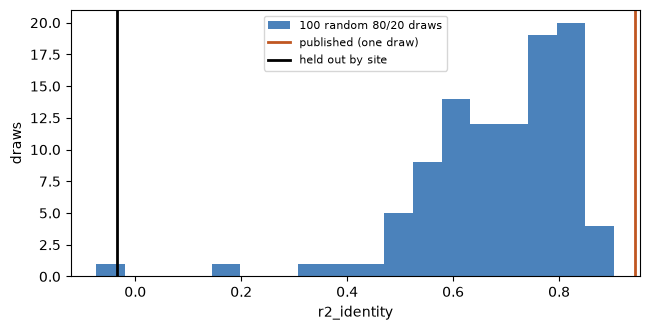

In [5]:
# Leave-one-site-out for the stacking arm, the protocol gap and the histogram
tested, predicted = [], []
for split in bf.leave_one_site_out(train):
    arm = factories["stacking"]().fit(split.train)
    tested += list(split.test)
    predicted += arm.predict(split.test)
held_out = bf.score(tested, predicted).r2_identity
gap = random_median - held_out
print(f"stacking: held out by site {held_out:.4f} | protocol gap (random median minus held out) {gap:.4f}")
print("committed gap:", round(benchmark["verdict"]["protocol_gap_random_minus_grouped"]["stacking"], 4))

fig, ax = plt.subplots(figsize=(6.6, 3.4))
ax.hist(random_scores["stacking"], bins=18, color="#2b6cb0", alpha=0.85, label="100 random 80/20 draws")
ax.axvline(bf.PUBLISHED_RANDOM_SPLIT_R2["stacking"], color="#c05621", lw=2, label="published (one draw)")
ax.axvline(held_out, color="black", lw=2, label="held out by site")
ax.set_xlabel("r2_identity")
ax.set_ylabel("draws")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## State of the art

- **Sui, Zhou, Zhao, Yang and Zou 2025** (https://doi.org/10.3390/app15031254) fit a stacking ensemble of a random forest and gradient boosting under a linear meta-learner on the 97 blasts and report a variance explained of 0.943 on one random 80/20 split. The SDD research basis records that the authors tried cross-validation and removed it, so the single split is the whole evidence.
- **Amoako, Jha and Zhong 2022** (https://doi.org/10.3390/mining2020013) fit support vector regressors with two kernels on the same rows and reach the opposite kernel conclusion from the 2025 study.
- Resampling that ignores dependence in the data can seriously underestimate prediction error (Roberts et al. 2017, https://doi.org/10.1111/ecog.02881).

The state of the art for the claim "a learned ensemble predicts fragmentation at 0.94" is therefore a single draw, with no spread and no campaign held out.

## Results

**The published figure is not a typical draw of its own protocol.** For the stacking ensemble all 100 reproduced draws fall below 0.943, and the median draw is far lower; for the polynomial-kernel regression most draws fall below the published figure. The published number is a favourable draw, or a draw with a different choice of parameters, not the expectation of the protocol. The notebook's medians and shares equal the committed ones.

**Duplicates do not explain it.** Collapsing the twins moves the stacking median by a few thousandths, so the high score is not memorised duplicates.

**The campaign does.** Held out by site, the same ensemble falls from a median near 0.70 to a score near zero, a protocol gap of about 0.74. The score a random split reports measures how well the model interpolates between blasts of campaigns it has already seen, which is a different question from how it behaves at a new mine.

**What this does not show.** It does not show the 0.943 is wrong as a statement about the authors' split; it shows it is one draw of a distribution, and that the distribution answers a question the practitioner is not asking. It also leaves open why: with ten campaigns, the held-out scores are noisy as well, and the next notebook weighs that.

## Summary

- A published score is one draw; the engine places it in 100 draws of its own protocol, and 0.943 lies above all of them for the stacking ensemble.
- Duplicated input vectors do not explain the gap; the shared campaign does.
- The gap between a random split and a campaign held out is about 0.74 for this arm.
- Next: notebook 04 shows the gap across every learned arm and why the protocol is the product's claim beyond the state of the art (level 4).

## References

- Sui, Zhou, Zhao, Yang and Zou 2025, https://doi.org/10.3390/app15031254 (the stacking ensemble, 0.943, 0.578)
- Amoako, Jha and Zhong 2022, https://doi.org/10.3390/mining2020013 (support vector regression on the same rows)
- Roberts et al. 2017, https://doi.org/10.1111/ecog.02881 (dependence in cross-validation)
- Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 (the corpus)
- `blastfrag` 0.4.0, the engine, on PyPI: https://pypi.org/project/blastfrag/